# Comparing hedge policies across sensitivities

This native Julia companion retains the public observations, original Float64 design, path seeds, initial policy weights, training budgets, cost accounting and risk preference. Shared primitive normal draws and unfitted parameters preserve the original numerical inputs; Julia computes all generated prices, fitted policies, gradients, cash flows and risk summaries. Timings measure the current native run. Displayed date indices retain the original zero-based convention. Figures use the requested dark theme and native outputs are saved under `outputs/julia`.

## Defining the benchmark hedges

At a preterminal date with remaining time $\tau$, the zero-rate Black-Scholes call delta is

$$
\Delta(S,\tau)=\Phi\!\left(\frac{\log(S/K)+\tfrac12\sigma^2\tau}{\sigma\sqrt{\tau}}\right).
$$

Here, $S$ is the current price, $K$ is the strike, $\sigma$ is the declared annual volatility, $\tau$ is remaining time, and $\Phi$ is the standard normal distribution function. This frictionless formula supplies a classical comparator. It is not treated as the optimum when costs are present.

### Common Independent Evaluation Paths

Row,Strategy,Entropic risk,Mean cash flow,Cash flow standard deviation,Fifth percentile,Mean loss in worst five percent,Mean turnover,Mean trading cost,Mean payoff
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Learned seed 3301,0.031404,-0.0300421,0.0293008,-0.0945894,0.11859,0.530783,0.00106157,0.028887
2,Learned seed 3302,0.0315226,-0.0306309,0.0239633,-0.0788033,0.0977474,0.800167,0.00160033,0.028887
3,Learned seed 3303,0.0314355,-0.0303949,0.0257734,-0.0846277,0.105965,0.692083,0.00138417,0.028887
4,Black-Scholes delta,0.0338714,-0.0338185,0.00593042,-0.0442285,0.0485049,2.40061,0.00480123,0.028887
5,Zero hedge,0.032104,-0.028887,0.0444593,-0.127133,0.159703,0.0,0.0,0.028887


Row,Rank in this sample,Strategy,Entropic risk,Difference from delta
,Int64,String,Float64,Float64
1,1,Learned seed 3301,0.031404,-0.00246746
2,2,Learned seed 3303,0.0314355,-0.00243588
3,3,Learned seed 3302,0.0315226,-0.00234879
4,4,Zero hedge,0.032104,-0.0017674
5,5,Black-Scholes delta,0.0338714,0.0


Row,Strategy,Maximum cash flow difference,Pass
,String,Float64,String
1,Learned seed 3301,0.0,Pass
2,Learned seed 3302,0.0,Pass
3,Learned seed 3303,0.0,Pass
4,Black-Scholes delta,0.0,Pass
5,Zero hedge,0.0,Pass


Row,Item,Value
,String,Any
1,Evaluation paths,8192
2,Evaluation seed,33999
3,Same paths for every strategy,Yes
4,Evaluation used to choose a training seed,No
5,Evaluation used to choose stopping time,No
6,Claim of global optimality,None


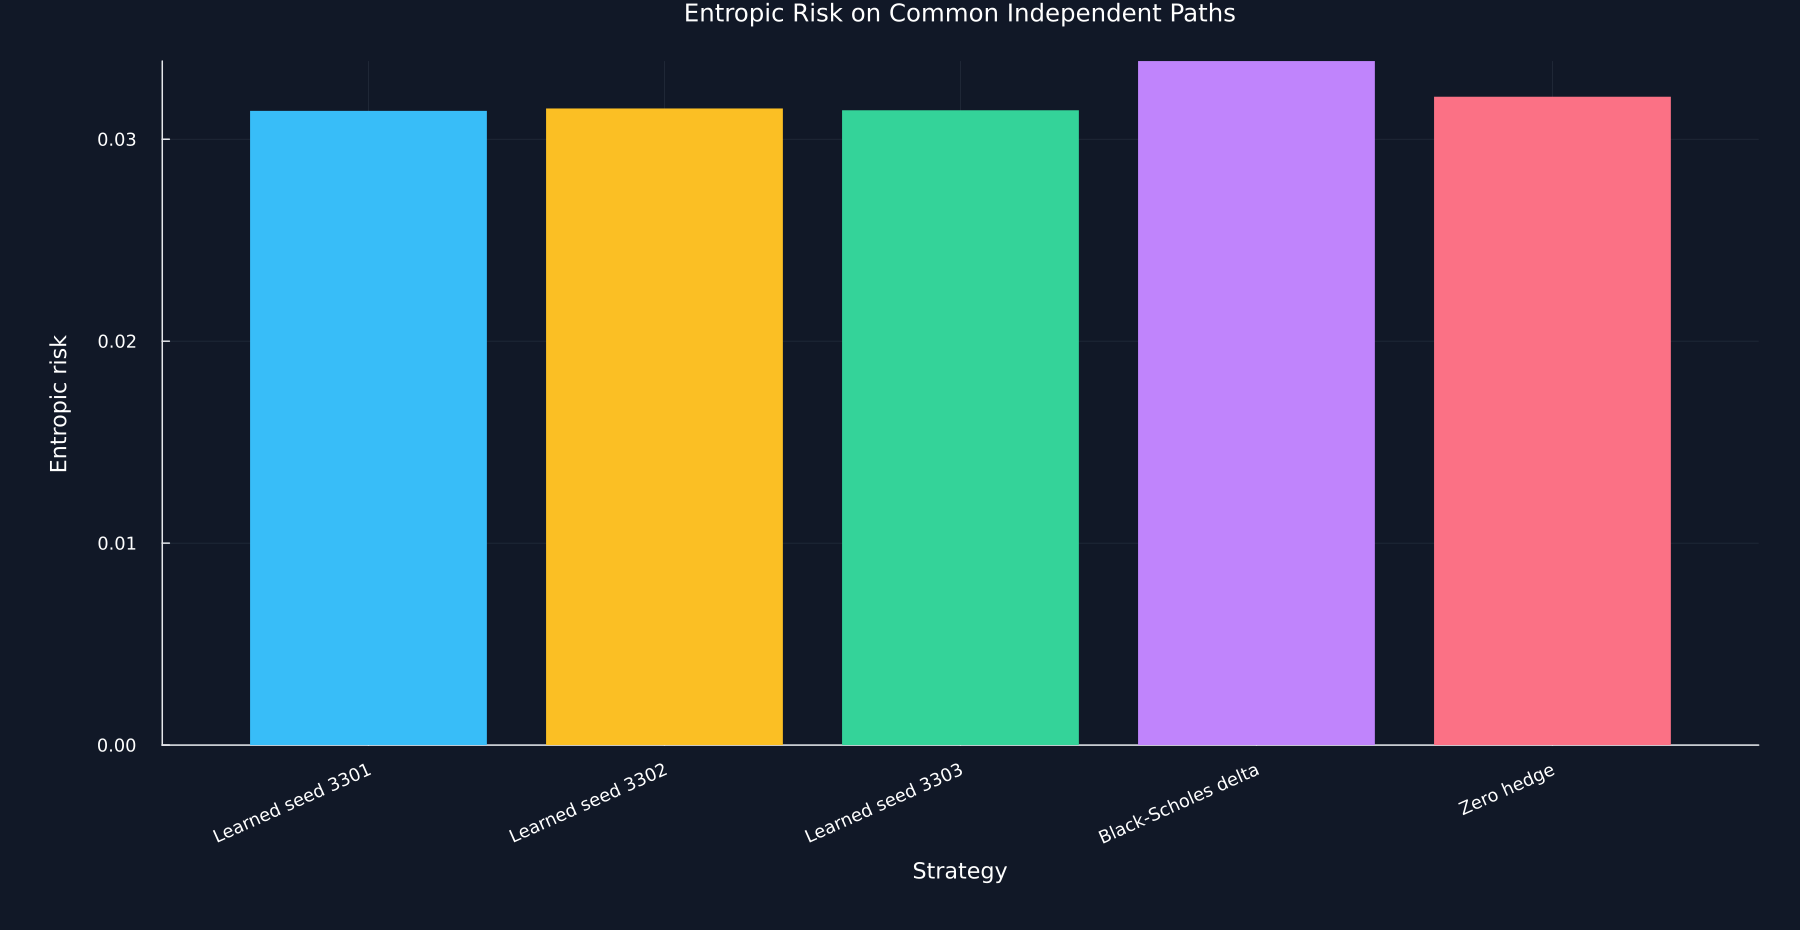

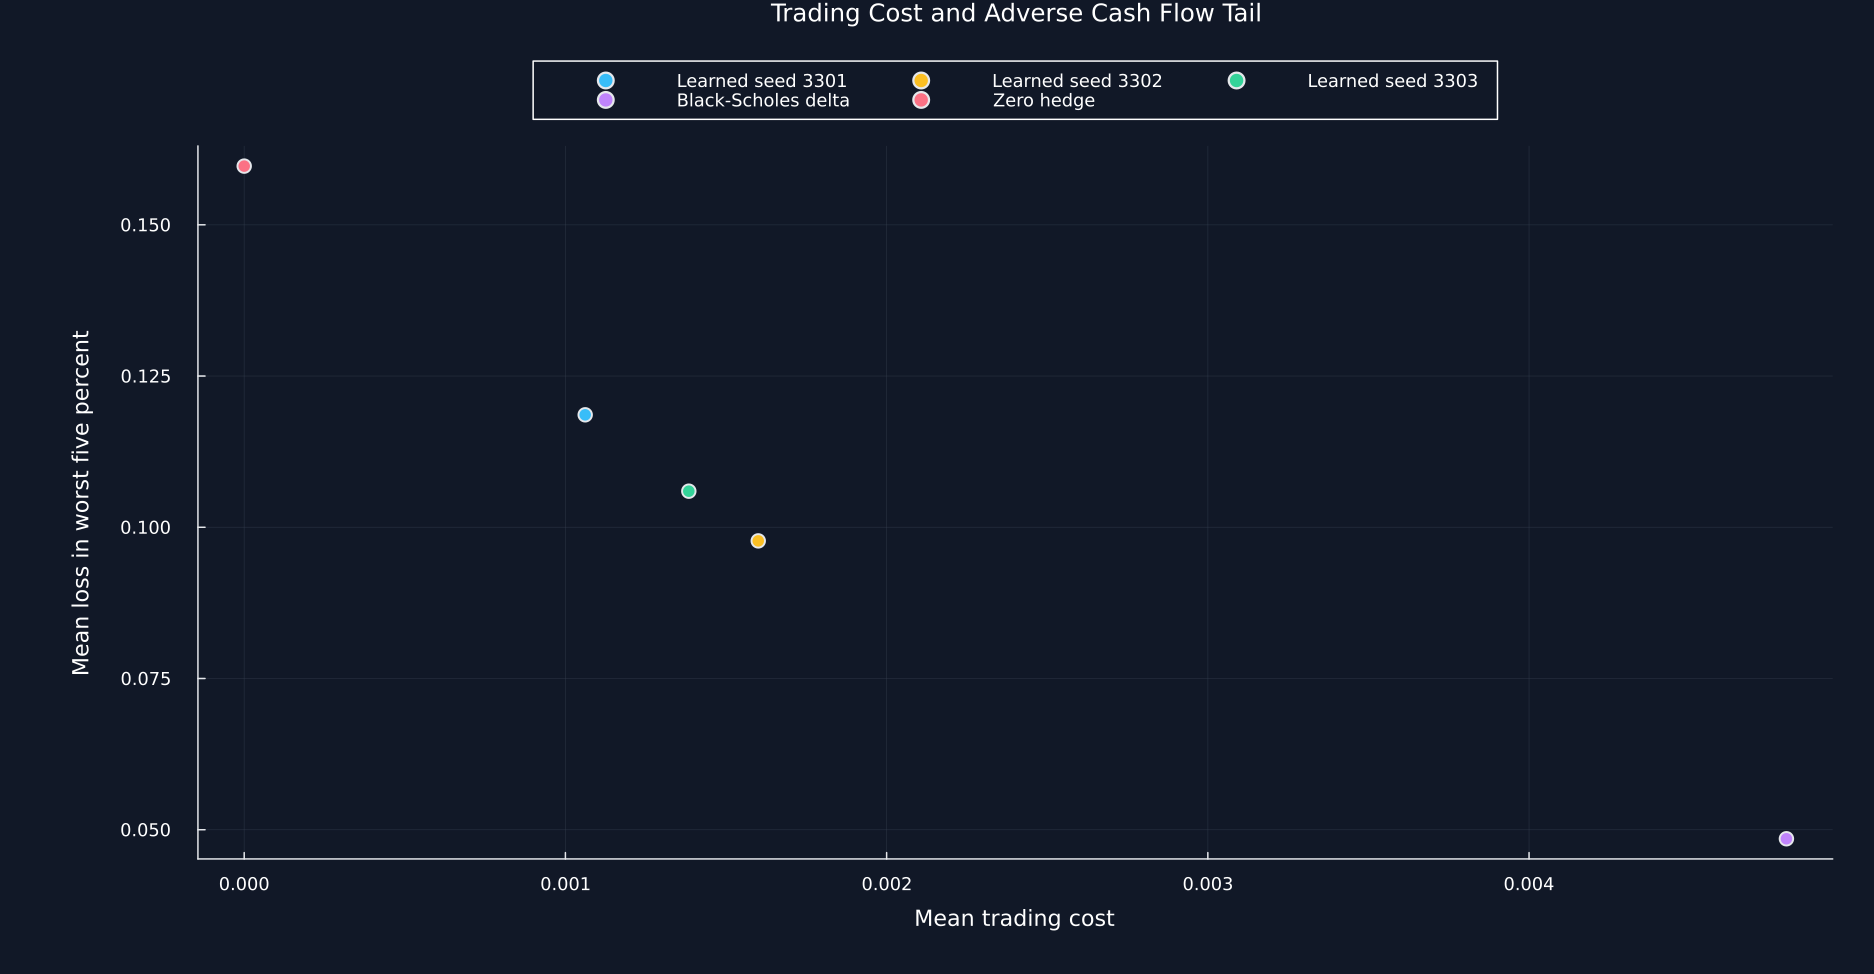

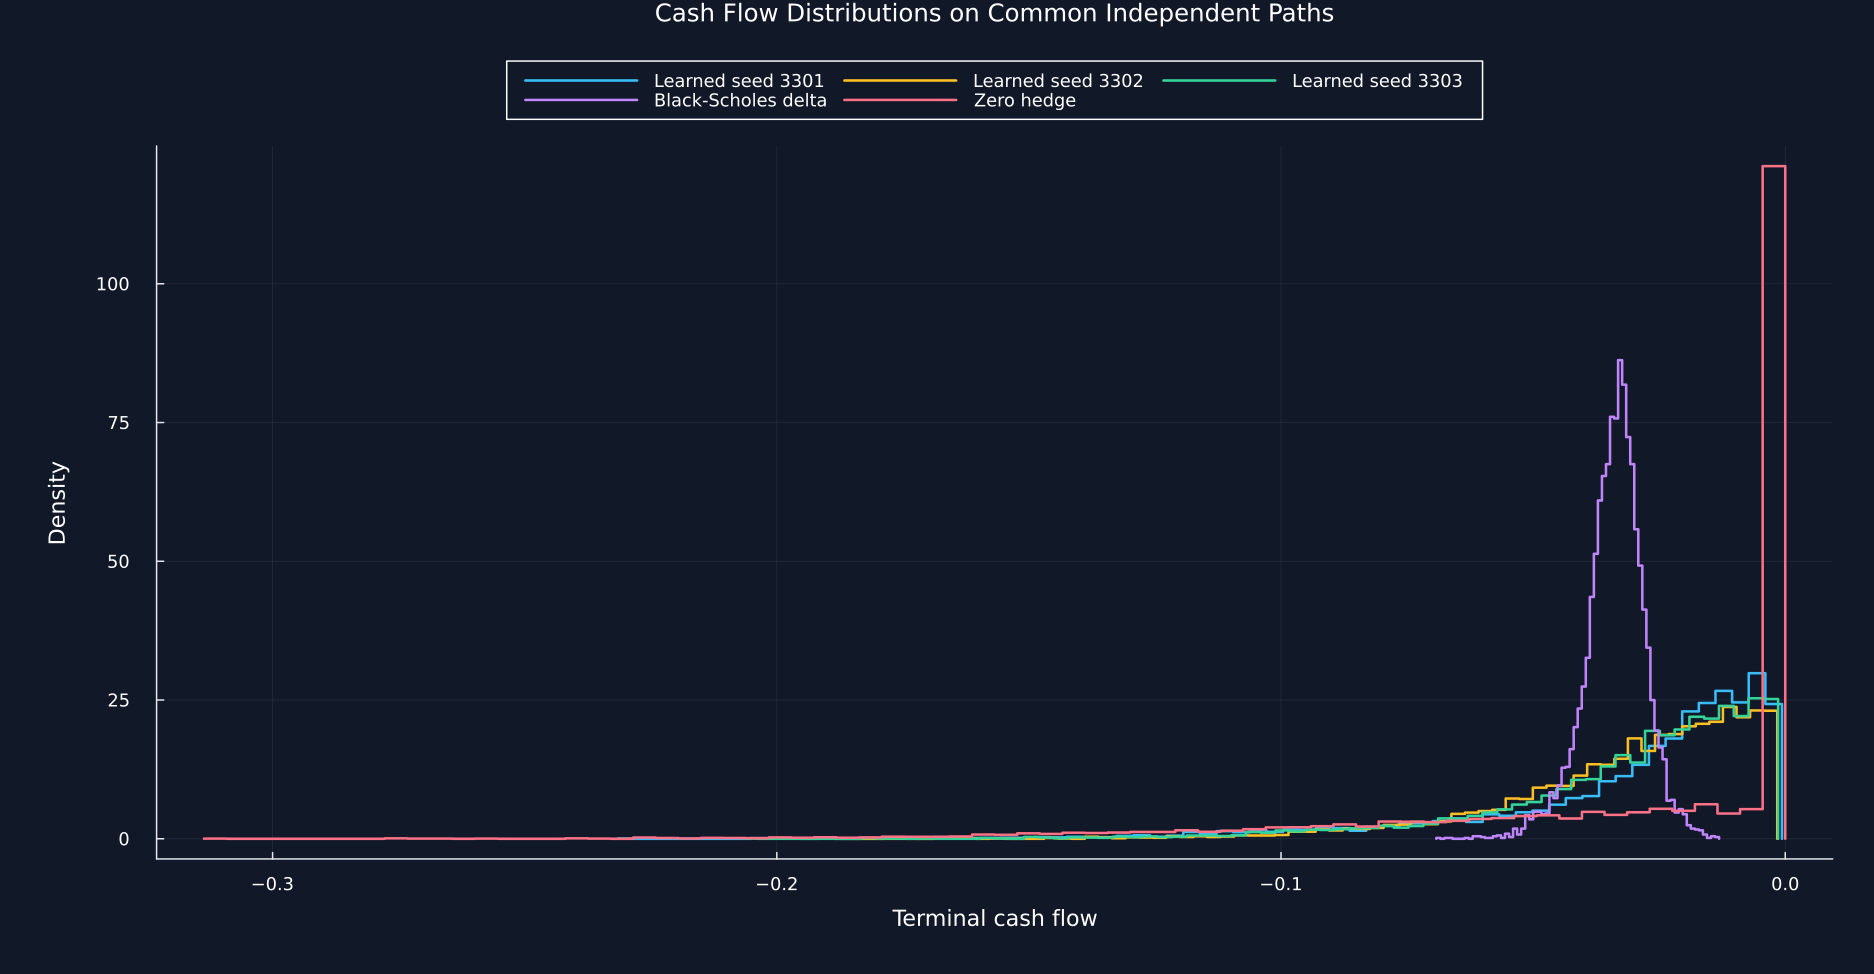

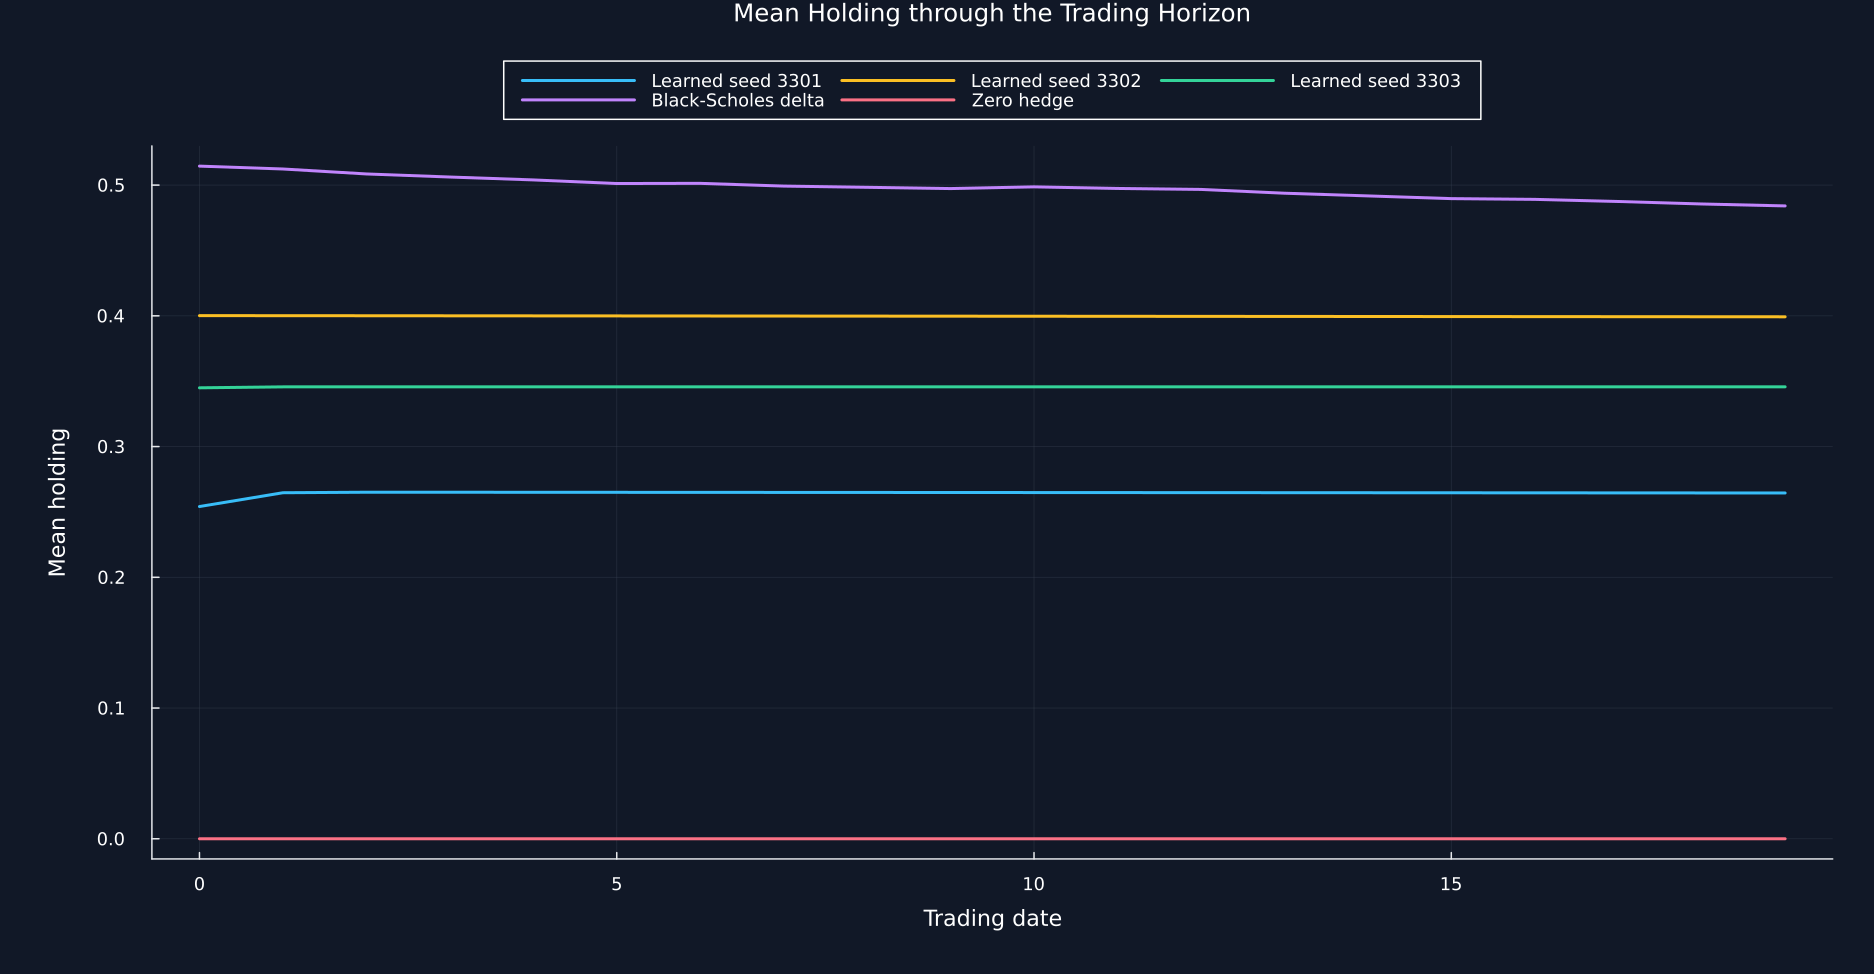

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("31_deep_hedging");
using CSV, TOML, Printf, Zygote
include(joinpath("..","support","BookHedging.jl"))
using .BookHedging
using RiskLabAI.Backtest: gbm_hedging_paths,black_scholes_call_delta,hedging_pnl,entropic_risk,DeepHedge,train_deep_hedge
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
random_root = joinpath("..","data","chapter31_random_inputs")
artifacts = joinpath(book_root(),"outputs","julia","artifacts","31_deep_hedging")
mkpath(artifacts)
data_file = dataset_path("fred_nasdaq")
full_public,public_design,public_observed,public_returns,sigma = public_volatility(data_file)
design = (spot=1.0,strike=1.0,maturity_days=30,maturity=30/365,volatility=sigma,drift=0.0,steps=20,cost_rate=.002,risk_aversion=3.0,hidden_size=16,learning_rate=.003,training_paths=2048,evaluation_paths=8192,iterations=200)
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter33-"*replace(name,"_"=>"-"))
    return nothing
end
function histogram_geometry(values,bins;density=false)
    lower,upper = extrema(values)
    if lower==upper
        lower,upper = lower-.5,upper+.5
    end
    edges = collect(range(lower,upper;length=bins+1))
    counts = zeros(Int,bins)
    for value in values
        index = clamp(searchsortedlast(edges,value),1,bins)
        counts[index] += 1
    end
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    return edges,heights
end
function draw_histogram!(figure,values,bins;color,label="",density=false,outline=false)
    edges,heights = histogram_geometry(values,bins;density)
    if outline
        x = vcat(edges[1],vec(permutedims(hcat(edges[1:end-1],edges[2:end]))),edges[end])
        y = vcat(0.0,repeat(heights;inner=2),0.0)
        plot!(figure,x,y;color,label,linewidth=1.7)
    else
        bar!(figure,(edges[1:end-1]+edges[2:end])/2,heights;bar_width=diff(edges),color,label,linealpha=0,alpha=.9)
    end
    return nothing
end
training_seeds = [3301,3302,3303]
evaluation_seed = 33999
evaluation_prices = hedge_paths(random_root,evaluation_seed,design.evaluation_paths,design.steps,sigma)
function fitted_model(seed)
    return DeepHedge(design.hidden_size;seed=seed*10+2,parameters=read_parameters(joinpath(artifacts,"deep_hedge_seed_$(seed).toml")))
end
strategies = Pair{String,Matrix{Float64}}[]
for seed in training_seeds
    model = fitted_model(seed)
    push!(strategies,"Learned seed $(seed)"=>model(evaluation_prices;strike=design.strike,maturity=design.maturity))
end
delta_positions = black_scholes_call_delta(evaluation_prices;strike=design.strike,maturity=design.maturity,volatility=design.volatility)
push!(strategies,"Black-Scholes delta"=>delta_positions,"Zero hedge"=>zeros(size(delta_positions)))
metrics = rename!(DataFrame([metric_record(name,evaluation_prices,positions,design.strike,design.cost_rate,design.risk_aversion) for (name,positions) in strategies]),METRIC_COLUMNS)
table(metrics,"deep_hedging_comparator_metrics","Independent outcomes for all learned policies and both comparators.")
ranking = sort(metrics[:,["Strategy","Entropic risk"]],"Entropic risk")
insertcols!(ranking,1,"Rank in this sample"=>1:nrow(ranking))
delta_risk = only(metrics[metrics.Strategy.=="Black-Scholes delta","Entropic risk"])
ranking[!,"Difference from delta"] = ranking[!,"Entropic risk"].-delta_risk
table(ranking,"deep_hedging_comparator_ranking","Risk ordering in this sample without policy selection.")
recalculation_rows = NamedTuple[]
pnl_frame = DataFrame()
for (name,positions) in strategies
    components = cashflow_components(evaluation_prices,positions,design.strike,design.cost_rate)
    released = hedging_pnl(evaluation_prices,positions;strike=design.strike,cost_rate=design.cost_rate)
    push!(recalculation_rows,(Strategy=name,difference=maximum(abs.(released-components.pnl)),Pass=all(isapprox.(released,components.pnl;atol=1e-13,rtol=0))))
    pnl_frame[!,name] = released
end
recalculation = rename!(DataFrame(recalculation_rows),["Strategy","Maximum cash flow difference","Pass"])
@assert all(recalculation.Pass)
table(recalculation,"deep_hedging_comparator_recalculation","Independent cash flow checks for every reported strategy.")
evaluation_contract = DataFrame("Item"=>["Evaluation paths","Evaluation seed","Same paths for every strategy","Evaluation used to choose a training seed","Evaluation used to choose stopping time","Claim of global optimality"],"Value"=>Any[design.evaluation_paths,evaluation_seed,"Yes","No","No","None"])
table(evaluation_contract,"deep_hedging_evaluation_contract","Rules for the independent strategy comparison.")
colors = [palette.cyan,palette.amber,palette.green,violet,palette.rose]
risk_figure = metrics[:,["Strategy","Entropic risk"]]
save_data(risk_figure,paths,"deep_hedging_comparator_risk")
figure = bar(1:5,risk_figure[!,"Entropic risk"];color=colors,linealpha=0,xticks=(1:5,risk_figure.Strategy),xrotation=24,title="Entropic Risk on Common Independent Paths",xlabel="Strategy",ylabel="Entropic risk",legend=false,size=(1200,620),bottom_margin=16Plots.mm)
save_figure(figure,paths,"deep_hedging_comparator_risk")
tail_cost = metrics[:,["Strategy","Mean trading cost","Mean loss in worst five percent","Entropic risk"]]
save_data(tail_cost,paths,"deep_hedging_tail_cost_comparison")
figure = plot(;title="Trading Cost and Adverse Cash Flow Tail",xlabel="Mean trading cost",ylabel="Mean loss in worst five percent",legend=:outertop,legend_columns=3,size=(1250,650),left_margin=16Plots.mm)
for (index,row) in enumerate(eachrow(tail_cost))
    scatter!(figure,[row["Mean trading cost"]],[row["Mean loss in worst five percent"]];color=colors[index],markersize=5,label=row.Strategy)
end
save_figure(figure,paths,"deep_hedging_tail_cost_comparison")
save_data(pnl_frame,paths,"deep_hedging_comparator_cashflows")
figure = plot(;title="Cash Flow Distributions on Common Independent Paths",xlabel="Terminal cash flow",ylabel="Density",legend=:outertop,legend_columns=3,size=(1250,650))
for (name,color) in zip(names(pnl_frame),colors)
    draw_histogram!(figure,pnl_frame[!,name],70;color,label=name,density=true,outline=true)
end
save_figure(figure,paths,"deep_hedging_comparator_cashflows")
mean_holdings = DataFrame("Trading date"=>0:design.steps-1)
figure = plot(;title="Mean Holding through the Trading Horizon",xlabel="Trading date",ylabel="Mean holding",legend=:outertop,legend_columns=3,size=(1250,650))
for ((name,positions),color) in zip(strategies,colors)
    mean_holdings[!,name] = vec(mean(positions;dims=1))
    plot!(figure,mean_holdings[!,"Trading date"],mean_holdings[!,name];color,label=name)
end
save_data(mean_holdings,paths,"deep_hedging_comparator_holdings")
save_figure(figure,paths,"deep_hedging_comparator_holdings")
nothing


## Sensitivity with One Change at a Time

For each sensitivity run, define the comparator gap as

$$
d=\widehat\rho_{\mathrm{learned}}-\widehat\rho_{\Delta}.
$$

Here, $\widehat\rho_{\mathrm{learned}}$ is the learned policy's entropic risk in this sample and $\widehat\rho_{\Delta}$ is the Black-Scholes delta risk on the same evaluation paths. A negative $d$ favors the learned policy in that declared run; a positive $d$ favors the delta comparator. This difference does not establish a general ranking.

### Testing hedge sensitivity across design choices

Row,Item,Value
,String,Real
1,Training paths per run,384
2,Evaluation paths per run,2048
3,Training iterations per run,50
4,Hidden units per layer,16
5,Learning rate,0.003
6,Training path seed,33701
7,Policy seed,33702
8,Evaluation seed,33703


Row,Value,Learned risk,Delta risk,Zero hedge risk,Learned minus delta,Training seconds,Finite
,Float64,Float64,Float64,Float64,Float64,Float64,String
1,0.0,0.0290665,0.0288771,0.0329511,0.000189417,99.2365,Pass
2,0.001,0.0303782,0.0312803,0.0329511,-0.000902116,1.23511,Pass
3,0.002,0.0313789,0.033685,0.0329511,-0.00230609,1.53314,Pass
4,0.005,0.0329033,0.0409074,0.0329511,-0.00800409,1.39386,Pass


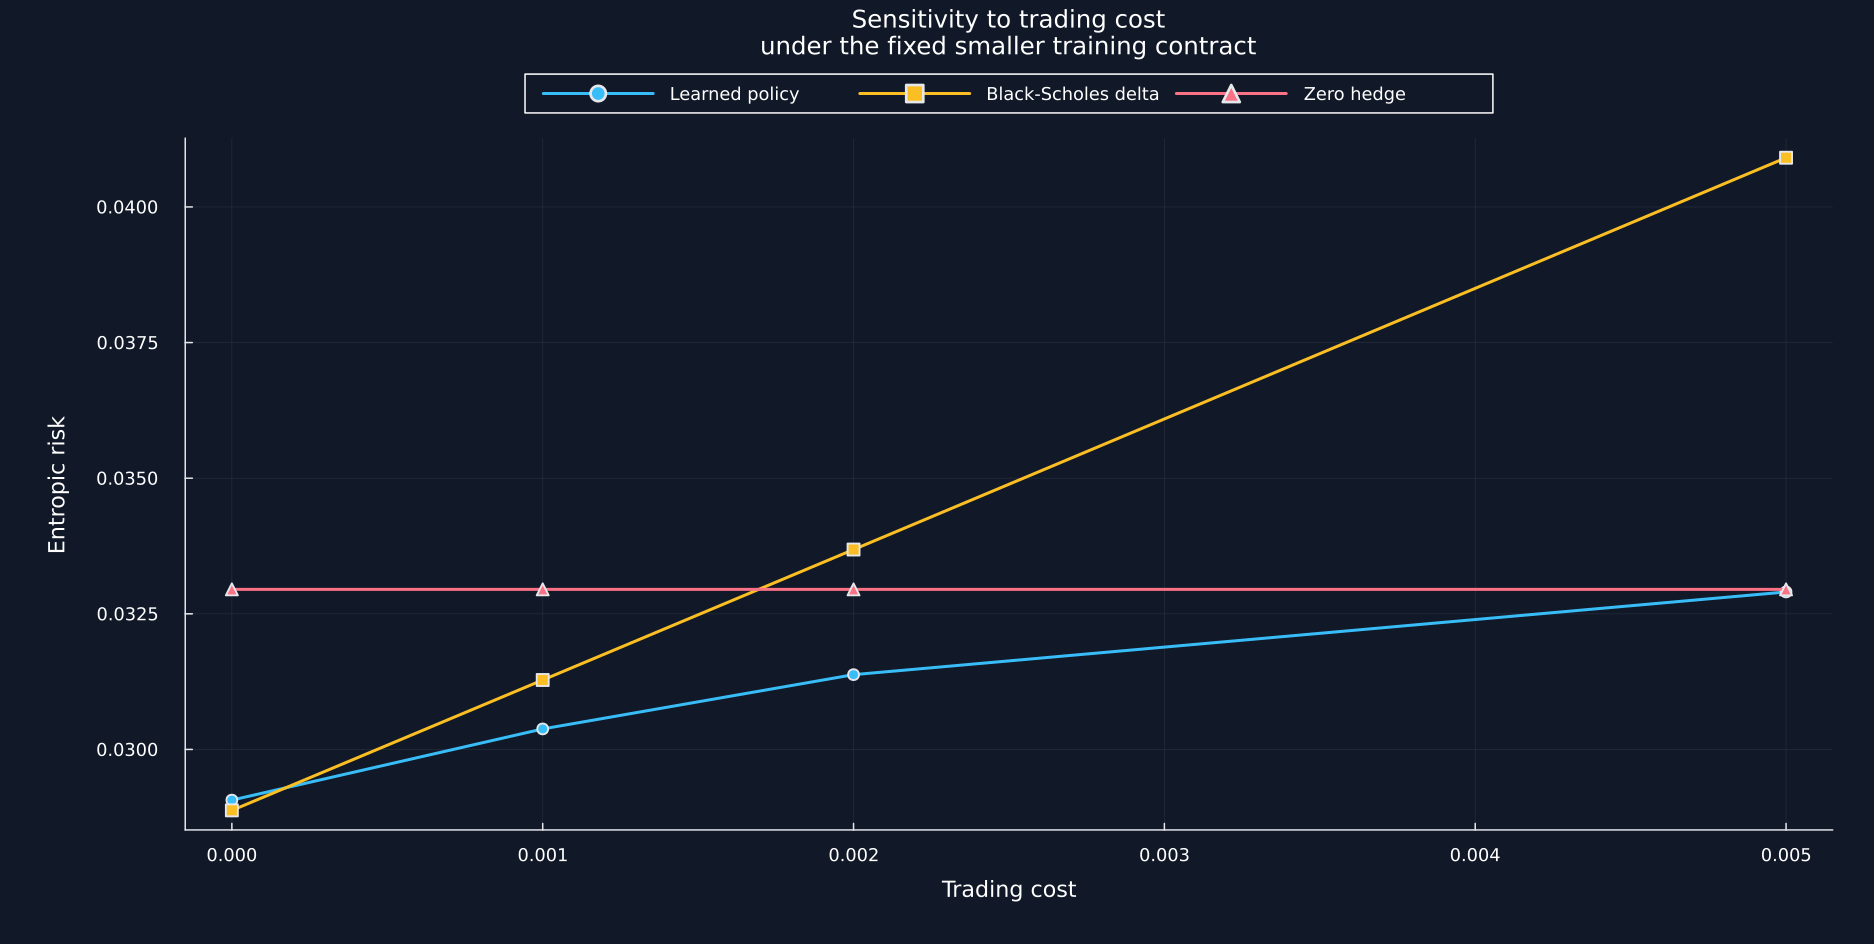

Row,Value,Learned risk,Delta risk,Zero hedge risk,Learned minus delta,Training seconds,Finite
,Float64,Float64,Float64,Float64,Float64,Float64,String
1,1.0,0.0307166,0.0336517,0.0307124,-0.00293515,1.04464,Pass
2,3.0,0.0313789,0.033685,0.0329511,-0.00230609,0.966655,Pass
3,10.0,0.0332803,0.0338028,0.0433483,-0.000522528,1.23654,Pass


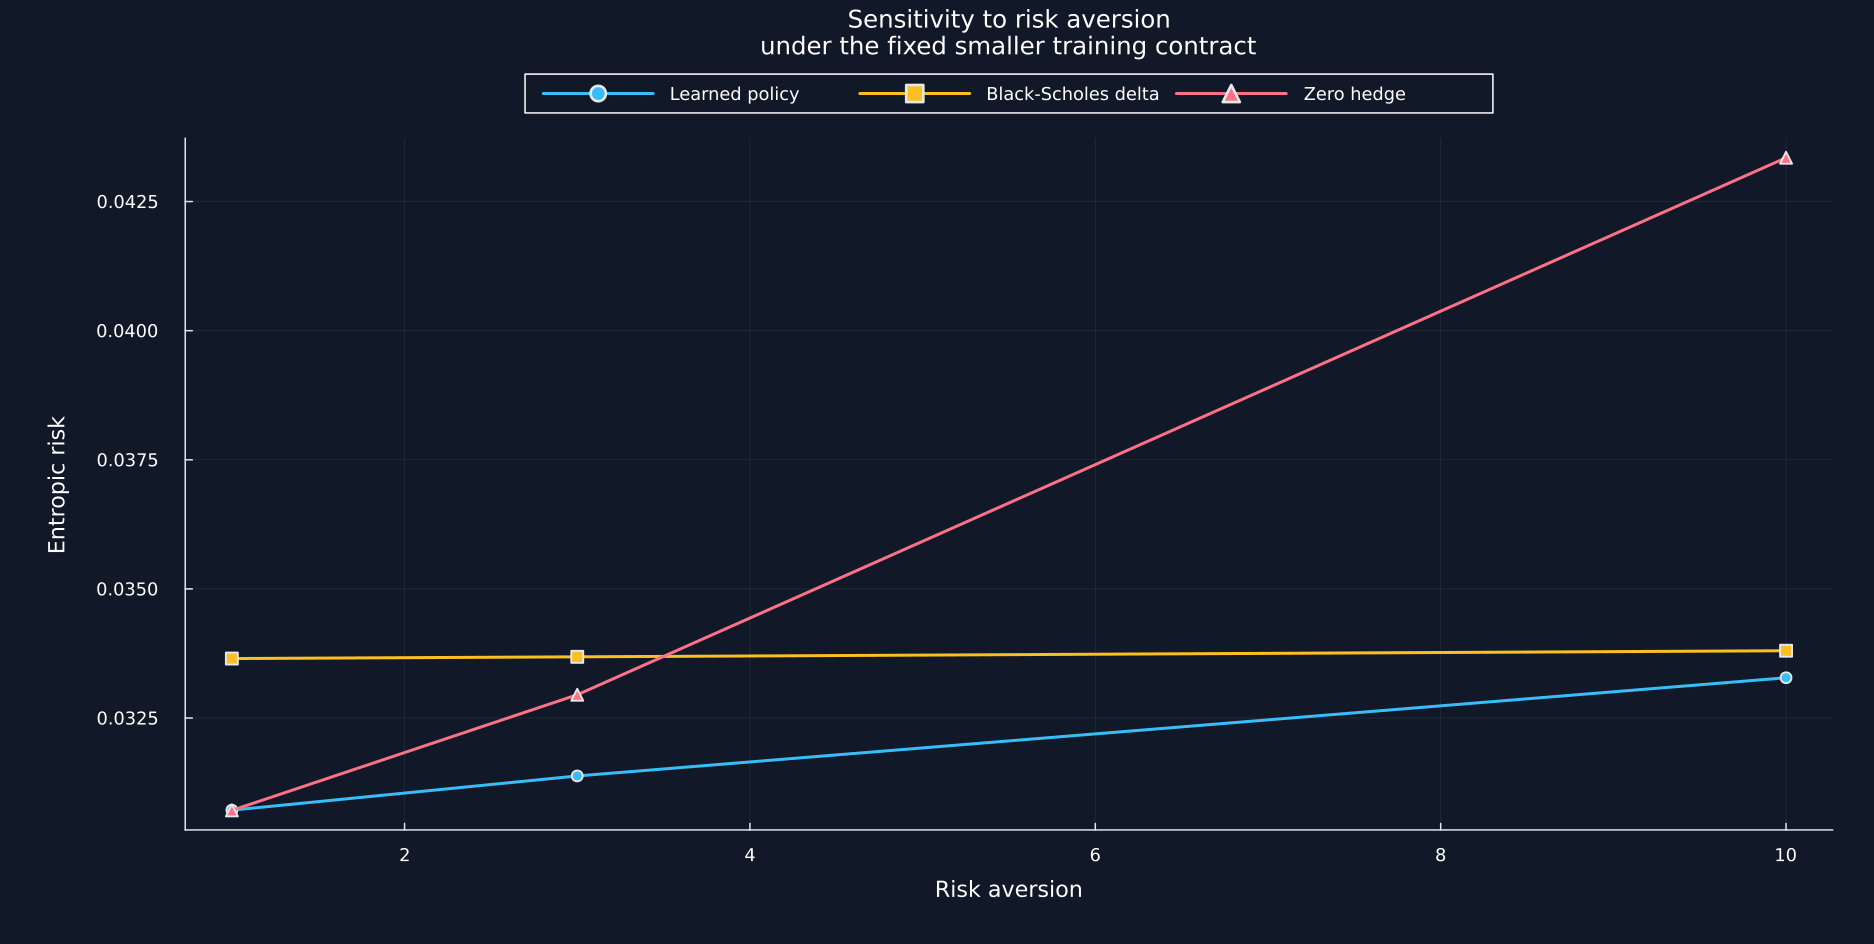

Row,Value,Learned risk,Delta risk,Zero hedge risk,Learned minus delta,Training seconds,Finite
,Float64,Float64,Float64,Float64,Float64,Float64,String
1,10.0,0.0343437,0.0329403,0.0346995,0.00140336,10.5001,Pass
2,20.0,0.0313789,0.033685,0.0329511,-0.00230609,1.37928,Pass
3,40.0,0.0316127,0.0350551,0.0325178,-0.00344233,155.638,Pass


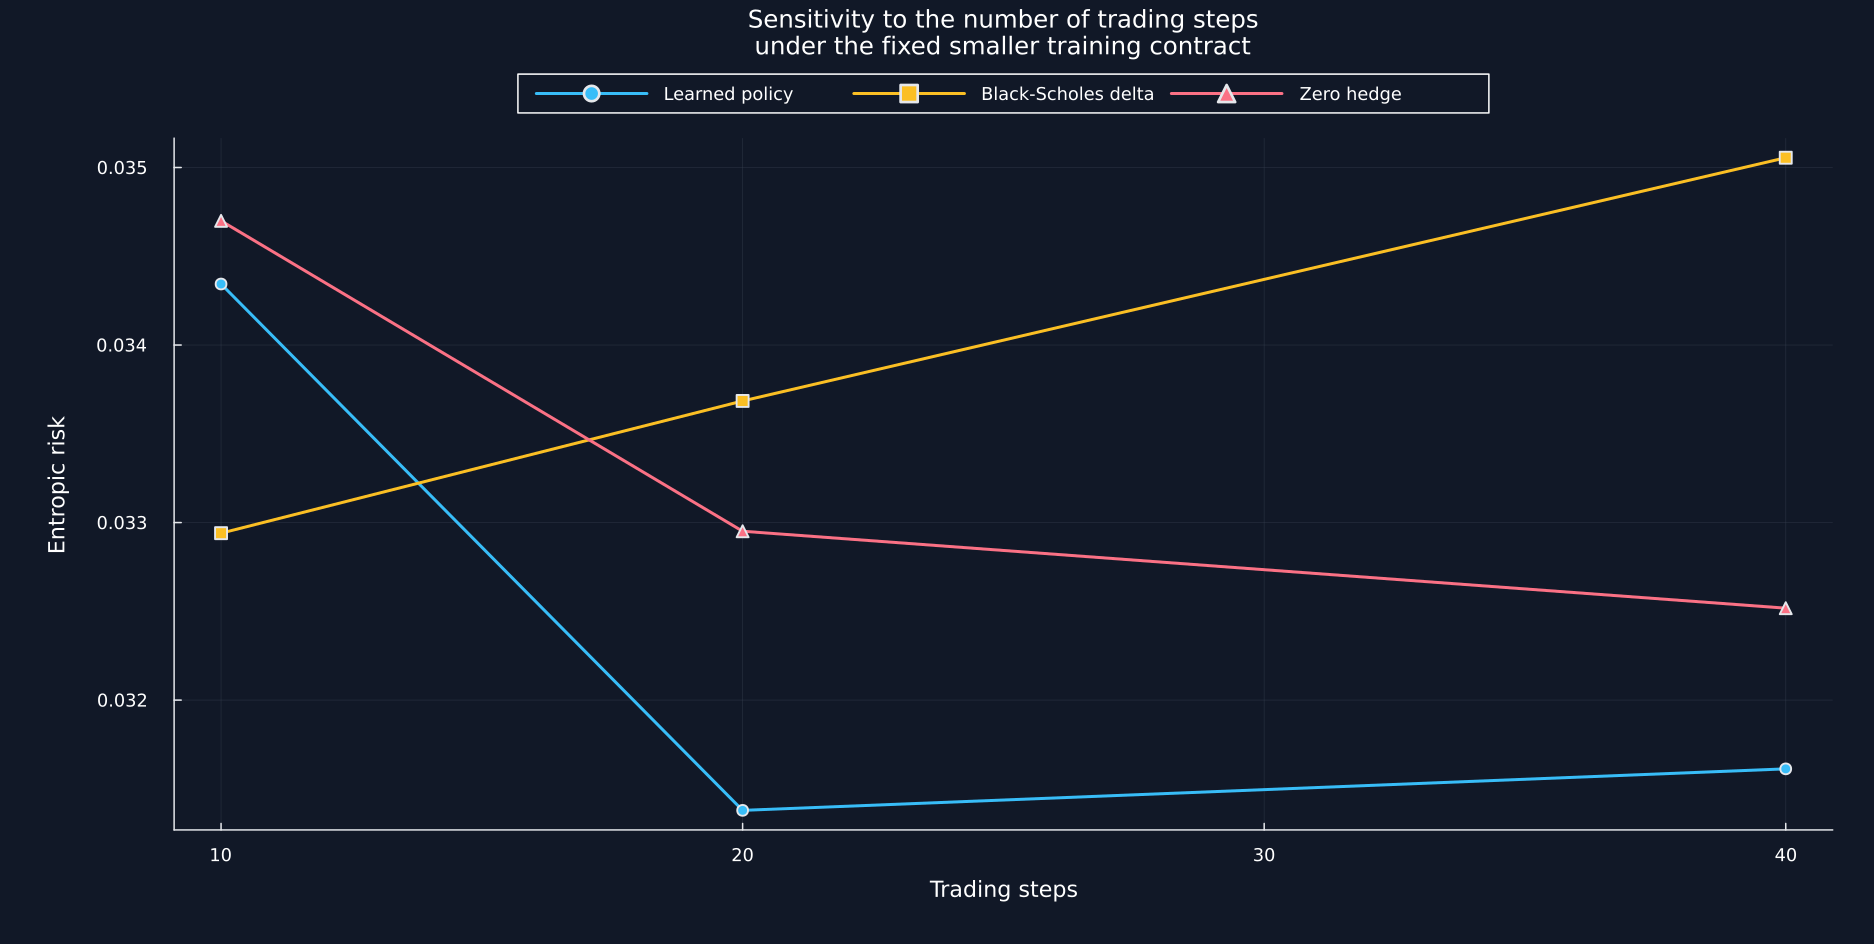

Row,Value,Learned risk,Delta risk,Zero hedge risk,Learned minus delta,Training seconds,Finite
,Float64,Float64,Float64,Float64,Float64,Float64,String
1,30.0,0.0313789,0.033685,0.0329511,-0.00230609,1.20363,Pass
2,60.0,0.0440531,0.0456803,0.0490872,-0.00162717,1.16486,Pass
3,90.0,0.0539021,0.0548874,0.0628723,-0.000985369,1.00843,Pass
4,180.0,0.0763984,0.0756582,0.100645,0.000740158,1.26377,Pass
5,360.0,0.108622,0.105012,0.190949,0.0036099,0.769784,Pass


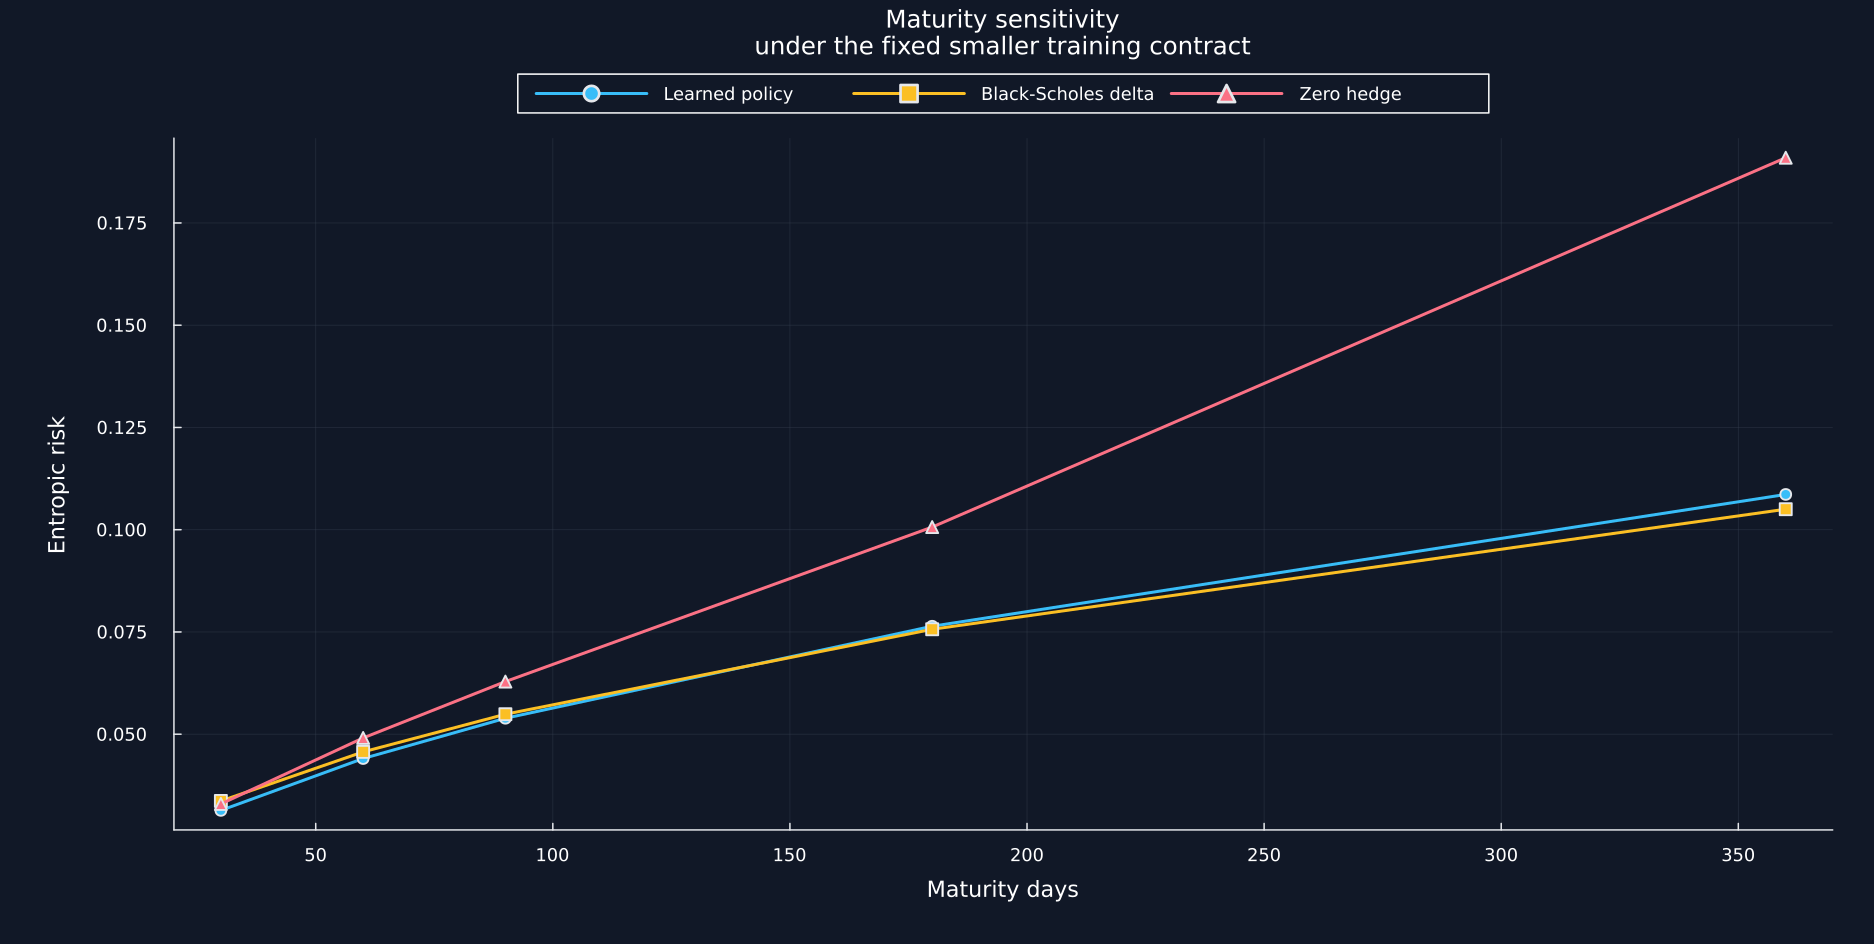

In [2]:
sensitivity_contract = (training_paths=384,evaluation_paths=2048,iterations=50,hidden_size=16,learning_rate=.003,training_seed=33701,model_seed=33702,evaluation_seed=33703)
contract_table = DataFrame("Item"=>["Training paths per run","Evaluation paths per run","Training iterations per run","Hidden units per layer","Learning rate","Training path seed","Policy seed","Evaluation seed"],"Value"=>collect(values(sensitivity_contract)))
table(contract_table,"deep_hedging_sensitivity_contract","Fixed contract for every sensitivity run with one change at a time.")
function sensitivity_run(factor,value,cost_rate,risk_aversion,steps,maturity_days)
    maturity = maturity_days/365
    training_prices = hedge_paths(random_root,sensitivity_contract.training_seed,sensitivity_contract.training_paths,steps,sigma;maturity)
    evaluation = hedge_paths(random_root,sensitivity_contract.evaluation_seed,sensitivity_contract.evaluation_paths,steps,sigma;maturity)
    fitted = initial_model(random_root,sensitivity_contract.model_seed)
    elapsed = @elapsed history = train_deep_hedge(fitted,training_prices;strike=design.strike,maturity,cost_rate,risk_aversion,iterations=sensitivity_contract.iterations,learning_rate=sensitivity_contract.learning_rate)
    fitted_positions = fitted(evaluation;strike=design.strike,maturity)
    delta_positions = black_scholes_call_delta(evaluation;strike=design.strike,maturity,volatility=sigma)
    zero_positions = zeros(size(delta_positions))
    risk(positions) = entropic_risk(hedging_pnl(evaluation,positions;strike=design.strike,cost_rate),risk_aversion)
    learned_risk,delta_risk,zero_risk = risk(fitted_positions),risk(delta_positions),risk(zero_positions)
    return (Factor=factor,Value=Float64(value),cost=cost_rate,aversion=risk_aversion,steps=steps,days=maturity_days,initial=history[1],final=history[end],learned=learned_risk,delta=delta_risk,zero=zero_risk,difference=learned_risk-delta_risk,seconds=elapsed,Finite=all(isfinite,history)&&all(isfinite,[learned_risk,delta_risk,zero_risk]))
end
sensitivity_rows = NamedTuple[]
for value in [0.,.001,.002,.005]
    push!(sensitivity_rows,sensitivity_run("Trading cost",value,value,design.risk_aversion,design.steps,design.maturity_days))
end
for value in [1.,3.,10.]
    push!(sensitivity_rows,sensitivity_run("Risk aversion",value,design.cost_rate,value,design.steps,design.maturity_days))
end
for value in [10,20,40]
    push!(sensitivity_rows,sensitivity_run("Trading steps",value,design.cost_rate,design.risk_aversion,value,design.maturity_days))
end
for value in [30,60,90,180,360]
    push!(sensitivity_rows,sensitivity_run("Maturity days",value,design.cost_rate,design.risk_aversion,design.steps,value))
end
sensitivity = rename!(DataFrame(sensitivity_rows),["Factor","Value","Cost rate","Risk aversion","Trading steps","Maturity days","Initial training risk","Final training risk","Learned risk","Delta risk","Zero hedge risk","Learned minus delta","Training seconds","Finite"])
@assert nrow(sensitivity)==15 && all(sensitivity.Finite)
CSV.write(joinpath(artifacts,"deep_hedging_sensitivity_raw.csv"),sensitivity)
table_specs = [("Trading cost","deep_hedging_cost_sensitivity","Sensitivity to trading cost under the fixed smaller training contract."),("Risk aversion","deep_hedging_risk_sensitivity","Sensitivity to risk aversion under the fixed smaller training contract."),("Trading steps","deep_hedging_step_sensitivity","Sensitivity to the number of trading steps under the fixed smaller training contract."),("Maturity days","deep_hedging_maturity_sensitivity","Maturity sensitivity under the fixed smaller training contract.")]
for (factor,stem,caption) in table_specs
    selected = sensitivity[sensitivity.Factor.==factor,["Value","Learned risk","Delta risk","Zero hedge risk","Learned minus delta","Training seconds","Finite"]]
    table(selected,stem,caption)
    save_data(selected,paths,stem)
    figure = plot(selected.Value,selected[!,"Learned risk"];color=palette.cyan,marker=:circle,label="Learned policy",title=replace(chop(caption;tail=1)," under"=>"
under"),xlabel=factor,ylabel="Entropic risk",legend=:outertop,legend_columns=3,size=(1250,630))
    plot!(figure,selected.Value,selected[!,"Delta risk"];color=palette.amber,marker=:square,label="Black-Scholes delta")
    plot!(figure,selected.Value,selected[!,"Zero hedge risk"];color=palette.rose,marker=:utriangle,label="Zero hedge")
    save_figure(figure,paths,stem)
end
nothing


## Checking seed variation within the declared scope

The retained seed spread is

$$
R_{\mathrm{seed}}=\max_j\widehat\rho_j-\min_j\widehat\rho_j.
$$

Here, $\widehat\rho_j$ is the independent evaluation risk for declared training seed $j$. The range $R_{\mathrm{seed}}$ describes fitting variation in this fixed experiment. It is not uncertainty about all possible model choices or future markets.

Row,Seed,Entropic risk,Mean cash flow,Cash flow standard deviation,Mean trading cost
,Int64,Float64,Float64,Float64,Float64
1,3301,0.031404,-0.0300421,0.0293008,0.00106157
2,3302,0.0315226,-0.0306309,0.0239633,0.00160033
3,3303,0.0314355,-0.0303949,0.0257734,0.00138417


Row,Quantity,Value
,String,Float64
1,Smallest entropic risk,0.031404
2,Largest entropic risk,0.0315226
3,Seed risk range,0.000118676
4,Declared seeds retained,3.0


Row,Factor,Runs,Mean training seconds,Maximum training seconds,All runs finite
,String,Int64,Float64,Float64,String
1,Maturity days,5,1.0821,1.26377,Pass
2,Risk aversion,3,1.08261,1.23654,Pass
3,Trading cost,4,25.8497,99.2365,Pass
4,Trading steps,3,55.8391,155.638,Pass


Row,Factor,Runs,Learned risk lower,Delta risk lower,Ties
,String,Int64,Int64,Int64,Int64
1,Maturity days,5,3,2,0
2,Risk aversion,3,3,0,0
3,Trading cost,4,3,1,0
4,Trading steps,3,2,1,0


Row,Question,Answer,Boundary
,String,String,String
1,Does the chapter prove a global optimum?,No,Fixed finite training only
2,Does it establish market performance?,No,Generated paths only
3,Does it claim superiority over delta?,No,All observed rankings are reported
4,Is the path law fitted to option prices?,No,Public volatility scale only
5,Are evaluation paths used for selection?,No,Independent final evaluation
6,Are private preliminary architectures copied?,No,Released RiskLabAI method only


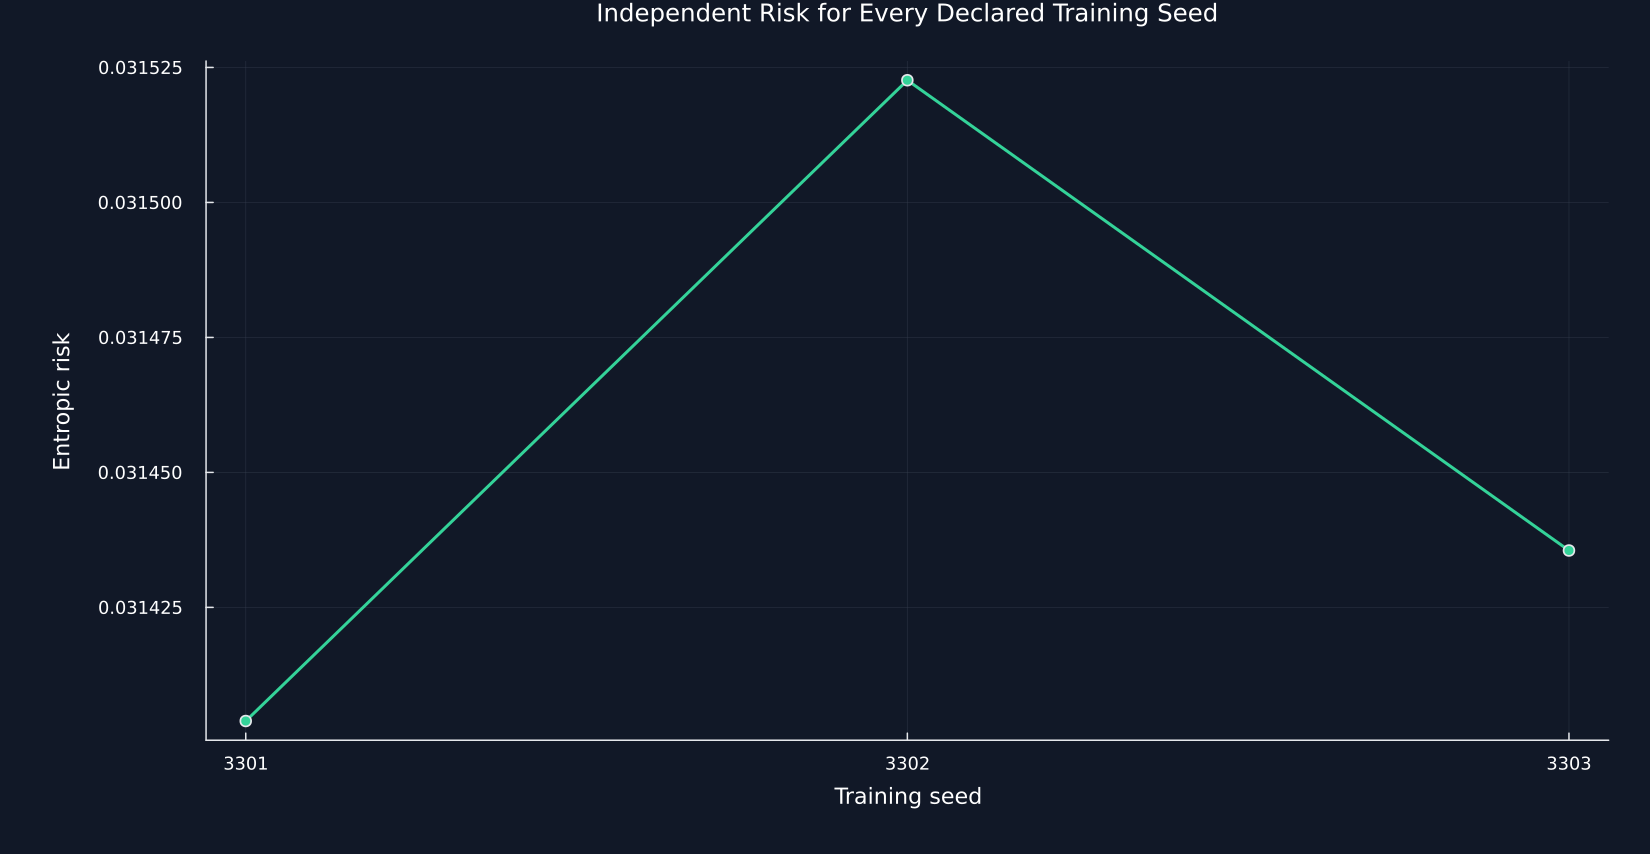

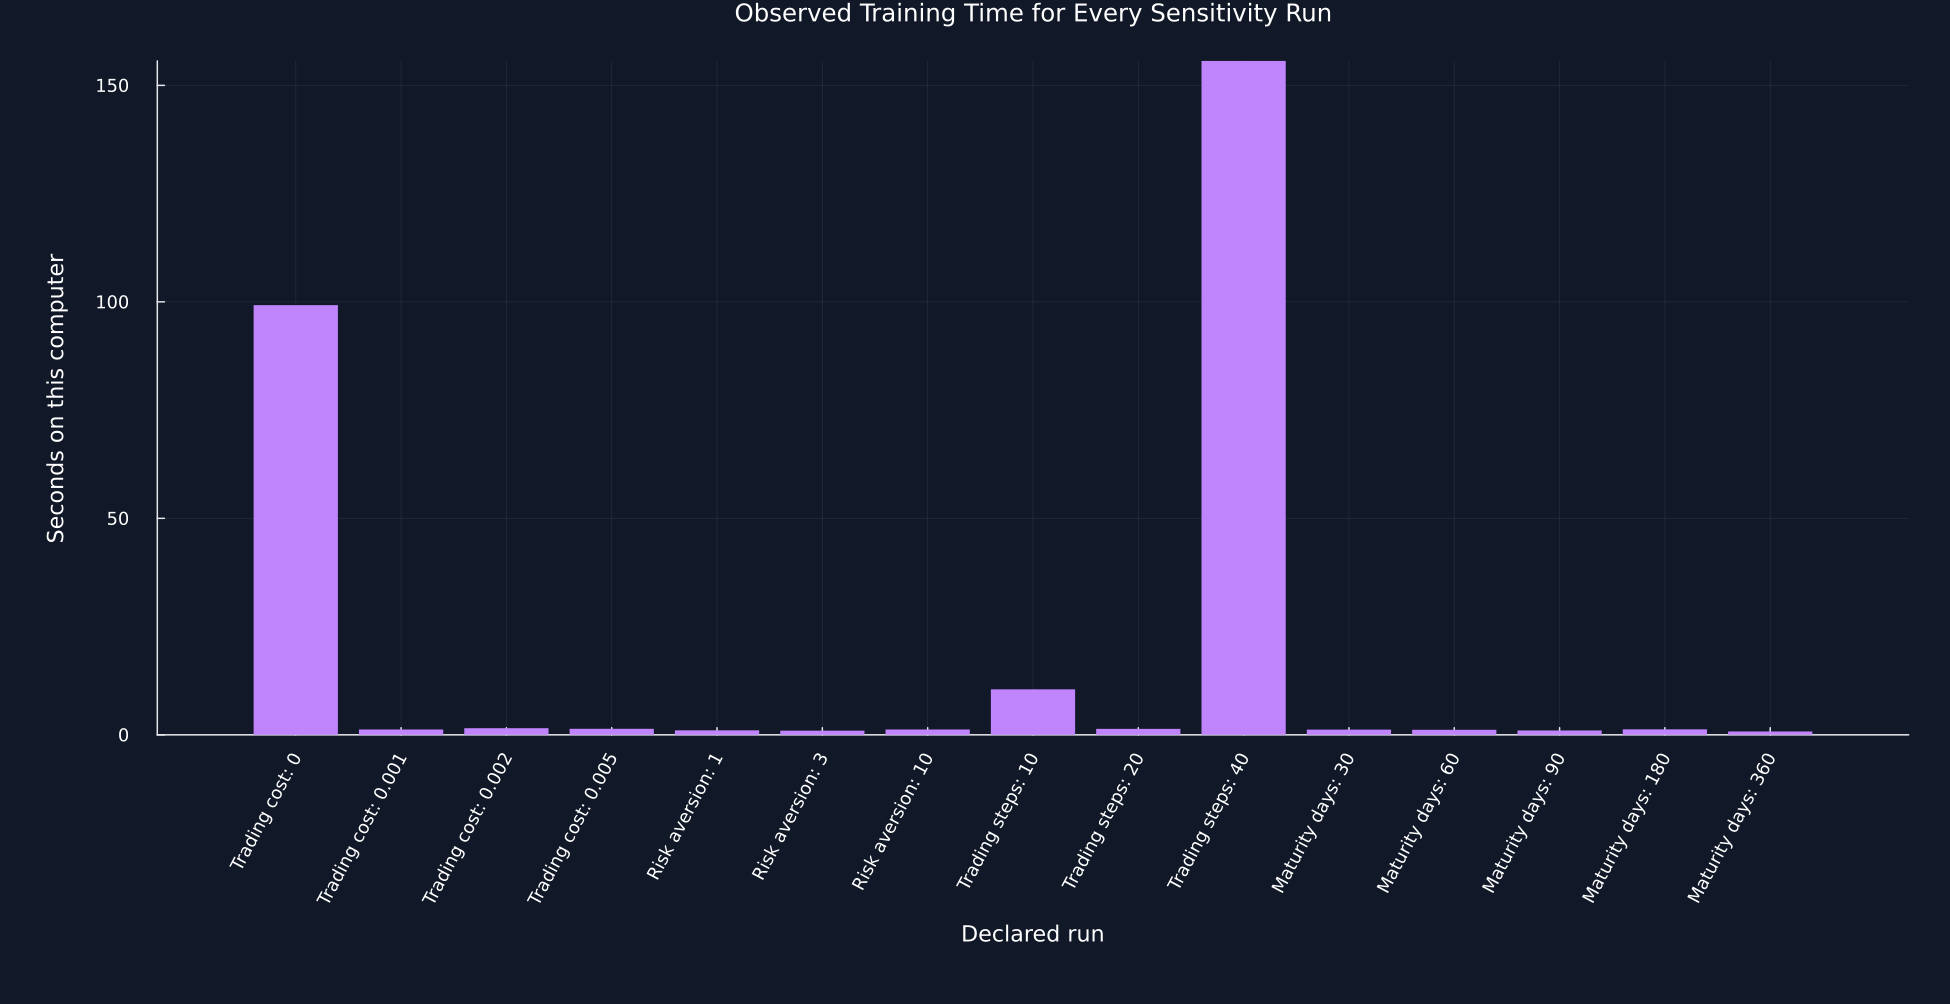

In [3]:
primary_metrics = CSV.read(joinpath(artifacts,"primary_evaluation_metrics.csv"),DataFrame)
seed_sensitivity = primary_metrics[:,["Strategy","Entropic risk","Mean cash flow","Cash flow standard deviation","Mean trading cost"]]
seed_sensitivity[!,"Seed"] = [parse(Int,match(r"\d+",name).match) for name in seed_sensitivity.Strategy]
select!(seed_sensitivity,["Seed","Entropic risk","Mean cash flow","Cash flow standard deviation","Mean trading cost"])
table(seed_sensitivity,"deep_hedging_seed_sensitivity","Independent results for every primary training seed.")
risks = seed_sensitivity[!,"Entropic risk"]
seed_range = DataFrame("Quantity"=>["Smallest entropic risk","Largest entropic risk","Seed risk range","Declared seeds retained"],"Value"=>[minimum(risks),maximum(risks),maximum(risks)-minimum(risks),nrow(seed_sensitivity)])
table(seed_range,"deep_hedging_seed_range","Observed spread across all declared primary seeds.")
timing = combine(groupby(sensitivity,:Factor;sort=true),:Value=>length=>"Runs","Training seconds"=>mean=>"Mean training seconds","Training seconds"=>maximum=>"Maximum training seconds",:Finite=>all=>"All runs finite")
table(timing,"deep_hedging_sensitivity_timing","Observed computer time for the bounded sensitivity groups.")
directions = combine(groupby(sensitivity,:Factor;sort=true),:Value=>length=>"Runs","Learned minus delta"=>(values->count(<(0),values))=>"Learned risk lower","Learned minus delta"=>(values->count(>(0),values))=>"Delta risk lower","Learned minus delta"=>(values->count(value->abs(value)<=1e-12,values))=>"Ties")
table(directions,"deep_hedging_sensitivity_directions","Comparison directions across the declared sensitivity runs.")
scope = DataFrame("Question"=>["Does the chapter prove a global optimum?","Does it establish market performance?","Does it claim superiority over delta?","Is the path law fitted to option prices?","Are evaluation paths used for selection?","Are private preliminary architectures copied?"],"Answer"=>fill("No",6),"Boundary"=>["Fixed finite training only","Generated paths only","All observed rankings are reported","Public volatility scale only","Independent final evaluation","Released RiskLabAI method only"])
table(scope,"deep_hedging_scope_boundaries","Interpretation boundaries for the generated hedging study.")
save_data(seed_sensitivity,paths,"deep_hedging_seed_sensitivity")
figure = plot(1:3,risks;xticks=(1:3,string.(seed_sensitivity.Seed)),color=palette.green,marker=:circle,title="Independent Risk for Every Declared Training Seed",xlabel="Training seed",ylabel="Entropic risk",legend=false,size=(1100,570))
save_figure(figure,paths,"deep_hedging_seed_sensitivity")
timing_figure = sensitivity[:,["Factor","Value","Training seconds"]]
value_label(value) = isinteger(value) ? string(Int(value)) : replace(@sprintf("%.6f",value),r"0+$"=>"")
timing_figure[!,"Run"] = timing_figure.Factor.*": ".*value_label.(timing_figure.Value)
save_data(timing_figure,paths,"deep_hedging_sensitivity_training_time")
figure = bar(1:nrow(timing_figure),timing_figure[!,"Training seconds"];color=violet,linealpha=0,xticks=(1:nrow(timing_figure),timing_figure.Run),xrotation=62,title="Observed Training Time for Every Sensitivity Run",xlabel="Declared run",ylabel="Seconds on this computer",legend=false,size=(1300,670),bottom_margin=24Plots.mm)
save_figure(figure,paths,"deep_hedging_sensitivity_training_time")
nothing
